# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [ ]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy

In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [127]:
print(df.dtypes)

Make                     str
Model                    str
Year                   int64
Engine Fuel Type         str
Engine HP            float64
Engine Cylinders     float64
Transmission Type        str
Driven_Wheels            str
Number of Doors      float64
Vehicle Size             str
Vehicle Style            str
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object


In [128]:
print(df.isna().sum())

Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64


In [129]:
rows = df[df.isna().any(axis=1)]
print(display(rows))

,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
539,FIAT,500e,2015,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,108,122,819,31800
540,FIAT,500e,2016,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,103,121,819,31800
541,FIAT,500e,2017,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,2.0,Compact,2dr Hatchback,103,121,819,31800
1983,Chevrolet,Bolt EV,2017,electric,200.0,NaN,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,110,128,1385,40905
1984,Chevrolet,Bolt EV,2017,electric,200.0,NaN,DIRECT_DRIVE,front wheel drive,4.0,Compact,4dr Hatchback,110,128,1385,36620
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9853,Kia,Soul EV,2016,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,Wagon,92,120,1720,31950
9854,Kia,Soul EV,2016,electric,NaN,0.0,DIRECT_DRIVE,front wheel drive,4.0,Compact,Wagon,92,120,1720,35950
11321,Suzuki,Verona,2004,NaN,155.0,6.0,AUTOMATIC,front wheel drive,4.0,Midsize,Sedan,25,17,481,17199
11322,Suzuki,Verona,2004,NaN,155.0,6.0,AUTOMATIC,front wheel drive,4.0,Midsize,Sedan,25,17,481,20199


None


In [130]:
print("Number of duplicates:", df.duplicated().sum())  
df_cleaned = df.drop_duplicates()

Number of duplicates: 720


In [131]:
# Explore here. Add as many cells as you need.
# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()

In [132]:
print(display(df.describe()))

,Year,Engine HP,Engine Cylinders,Number of Doors,highway MPG,city mpg,Popularity,MSRP
count,11914.000000,11845.00000,11884.000000,11908.000000,11914.000000,11914.000000,11914.000000,1.191400e+04
mean,2010.384338,249.38607,5.628829,3.436093,26.637485,19.733255,1554.911197,4.059474e+04
std,7.579740,109.19187,1.780559,0.881315,8.863001,8.987798,1441.855347,6.010910e+04
min,1990.000000,55.00000,0.000000,2.000000,12.000000,7.000000,2.000000,2.000000e+03
25%,2007.000000,170.00000,4.000000,2.000000,22.000000,16.000000,549.000000,2.100000e+04
50%,2015.000000,227.00000,6.000000,4.000000,26.000000,18.000000,1385.000000,2.999500e+04
75%,2016.000000,300.00000,6.000000,4.000000,30.000000,22.000000,2009.000000,4.223125e+04
max,2017.000000,1001.00000,16.000000,4.000000,354.000000,137.000000,5657.000000,2.065902e+06


None


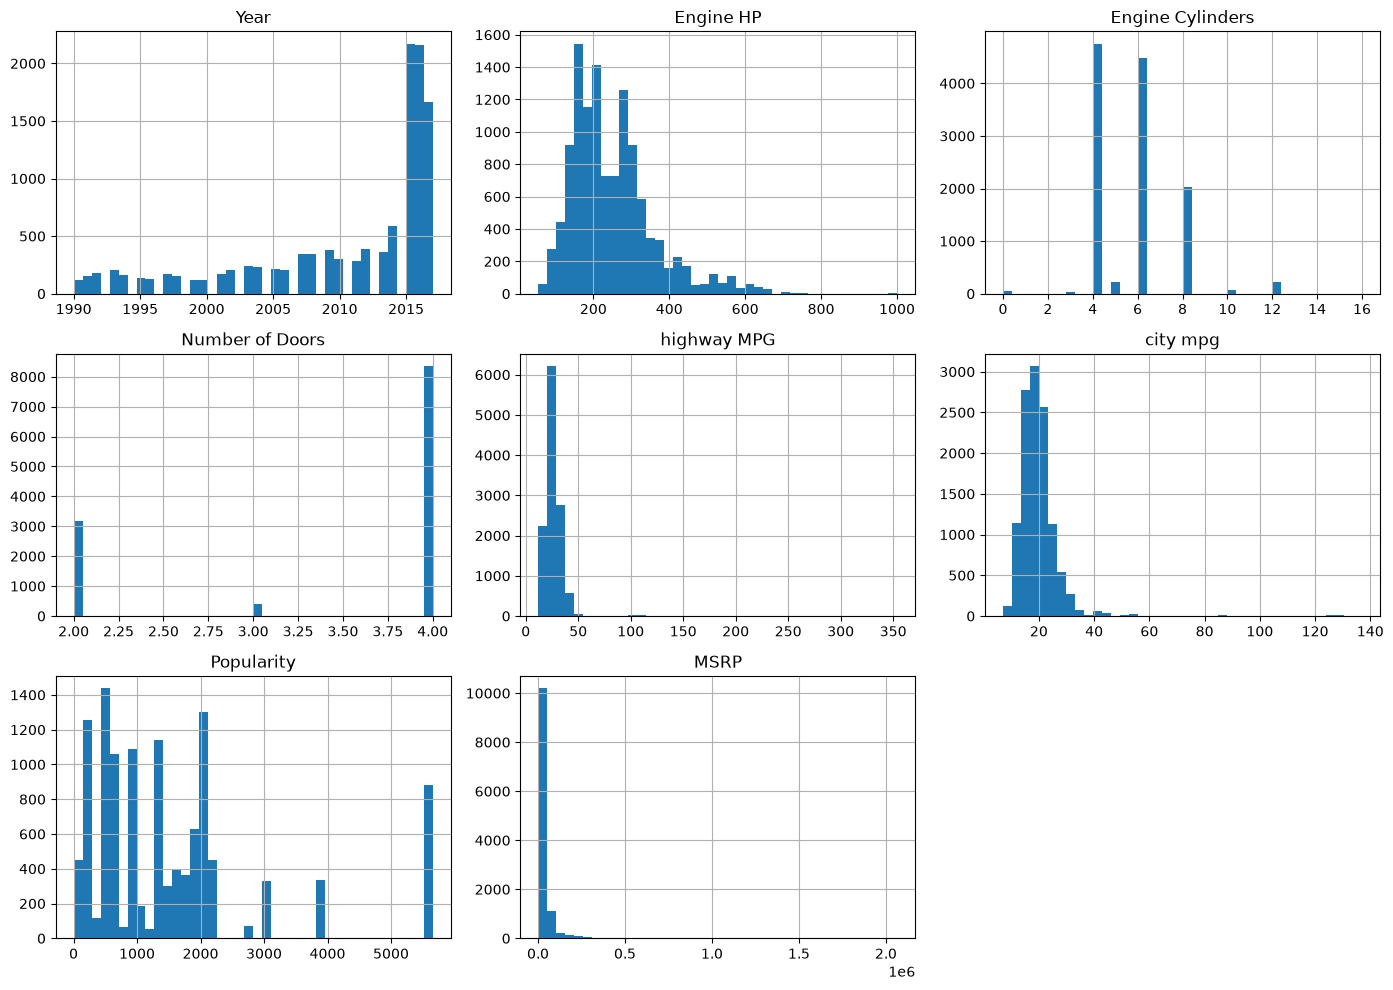

In [133]:
num_cols = df.select_dtypes(include='number').columns
df[num_cols].hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

# x-axis: the numeric columns
# y-axis: the number of rows for those x values 

In [134]:
df_cleaned['MSRP'].value_counts()



MSRP
2000     747
29995     18
25995     17
20995     15
27995     15
        ... 
56570      1
50520      1
46120      1
50620      1
50920      1
Name: count, Length: 6049, dtype: int64

In [135]:
df_cleaned['MSRP'] = df['MSRP'].replace(2000, np.nan)

In [136]:
electric = df_cleaned['Engine Fuel Type'] == 'electric'
print((electric & df['highway MPG'].notna() & df['city mpg'].notna()).sum())



66


In [137]:
df_cleaned.loc[electric, ['highway MPG', 'city mpg']] = np.nan

In [138]:
for col in df_cleaned.select_dtypes(include='object').columns:
    print(display(df[col].value_counts()))

/var/folders/wt/qhml1_wd0pg9_vmhgrlfzc9c0000gn/T/ipykernel_33667/3211039384.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_cleaned.select_dtypes(include='object').columns:


Make
Chevrolet        1123
Ford              881
Volkswagen        809
Toyota            746
Dodge             626
Nissan            558
GMC               515
Honda             449
Mazda             423
Cadillac          397
Mercedes-Benz     353
Suzuki            351
BMW               334
Infiniti          330
Audi              328
Hyundai           303
Volvo             281
Subaru            256
Acura             252
Kia               231
Mitsubishi        213
Lexus             202
Buick             196
Chrysler          187
Pontiac           186
Lincoln           164
Oldsmobile        150
Land Rover        143
Porsche           136
Saab              111
Aston Martin       93
Plymouth           82
Bentley            74
Ferrari            69
FIAT               62
Scion              60
Maserati           58
Lamborghini        52
Rolls-Royce        31
Lotus              29
Tesla              18
HUMMER             17
Maybach            16
Alfa Romeo          5
McLaren             5
Spyke

None


Model
Silverado 1500        156
Tundra                140
F-150                 126
Sierra 1500            90
Beetle Convertible     89
                     ... 
Syclone                 1
V90                     1
XC                      1
Yukon Denali            1
Zephyr                  1
Name: count, Length: 915, dtype: int64

None


...

None


Vehicle Size
Compact    4764
Midsize    4373
Large      2777
Name: count, dtype: int64

None


Vehicle Style
Sedan                  3048
4dr SUV                2488
Coupe                  1211
Convertible             793
4dr Hatchback           702
Crew Cab Pickup         681
Extended Cab Pickup     623
Wagon                   592
2dr Hatchback           506
Passenger Minivan       417
Regular Cab Pickup      392
2dr SUV                 138
Passenger Van           128
Cargo Van                95
Cargo Minivan            71
Convertible SUV          29
Name: count, dtype: int64

None


In [139]:
df_cleaned['Transmission Type'] = df_cleaned['Transmission Type'].replace('UNKNOWN', np.nan)

In [140]:
for col in df_cleaned.select_dtypes(include='number').columns:
    top = df_cleaned[col].nlargest(3).values
    max_val = df_cleaned[col].max()
    rows = (df_cleaned[col] == max_val).sum()
    print(f"{col}: top 3 = {top} | largest value {max_val} appears in {rows} row(s)")

Year: top 3 = [2017 2017 2017] | largest value 2017 appears in 1624 row(s)
Engine HP: top 3 = [1001. 1001. 1001.] | largest value 1001.0 appears in 3 row(s)
Engine Cylinders: top 3 = [16. 16. 16.] | largest value 16.0 appears in 3 row(s)
Number of Doors: top 3 = [4. 4. 4.] | largest value 4.0 appears in 7956 row(s)
highway MPG: top 3 = [354.  53.  53.] | largest value 354.0 appears in 1 row(s)
city mpg: top 3 = [58. 58. 55.] | largest value 58.0 appears in 2 row(s)
Popularity: top 3 = [5657 5657 5657] | largest value 5657 appears in 824 row(s)
MSRP: top 3 = [2065902. 1705769. 1500000.] | largest value 2065902.0 appears in 1 row(s)


In [141]:
df_cleaned = df_cleaned.drop(df_cleaned['highway MPG'].idxmax())

**Cleaning log:** fill in one row per problem.

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | the missings rows/columns | Using isna() function | 102 rows | left it | Not sure if those rows are value since only specific columns are missing like Engine |
| 2 | Duplicate rows | using duplicate() | 720 | Removed | to prevent inaccurate calculations |
| 3 | msrp $2000 for 747 rows | using value counts | 747 | set to NaN | this are unreliable to calculations |
| 4 | electric cars won't have high mpg | looking at the histogram | 66 | set to NaN | setting to NaN will not affect the other calculations |
| 5 | Unknown values | value counts | 19 | set to NaN | NaN indicates missing values |
| 6 | very high mrsp | nlargest | 1 | removed | Its an outlier |


In [142]:
# Build your cleaned DataFrame. Start from a copy so df stays untouched.
clean = df_cleaned.copy()
clean.columns = clean.columns.str.strip().str.lower().str.replace(" ", "_")  # freebie: snake_case names

In [143]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11193, 15)
engine_fuel_type       3
engine_hp             69
engine_cylinders      30
transmission_type     12
number_of_doors        6
highway_mpg           66
city_mpg              66
msrp                 747
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: $44,788
Median MSRP: $31,868


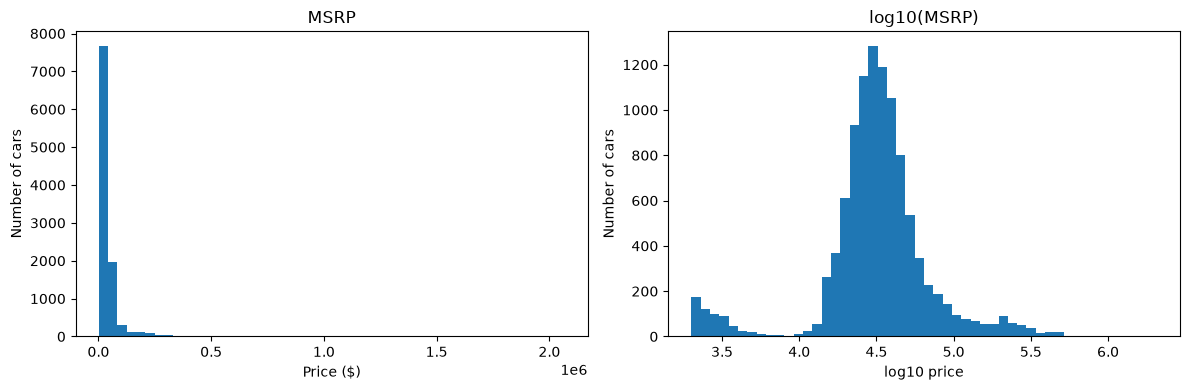

Share above mean: 24.4%


In [144]:
# a) mean and median
msrp = clean["msrp"].dropna()
print(f"Mean MSRP: ${msrp.mean():,.0f}")
print(f"Median MSRP: ${msrp.median():,.0f}")

# b) two histograms side by side (plt.subplots(1, 2))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(msrp, bins=50)
axes[0].set_title("MSRP")
axes[0].set_xlabel("Price ($)")
axes[0].set_ylabel("Number of cars")
axes[1].hist(np.log10(msrp), bins=50)
axes[1].set_title("log10(MSRP)")
axes[1].set_xlabel("log10 price")
axes[1].set_ylabel("Number of cars")
plt.tight_layout()
plt.show()

# c) share of cars above the mean
print(f"Share above mean: {(msrp > msrp.mean()).mean():.1%}")


**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [145]:
# a) mean and std of highway_mpg by vehicle_size, 2017 only
clean_2017 = clean[clean["year"] == 2017]
print(clean_2017.groupby("vehicle_size")["highway_mpg"].agg(["mean", "std"]))

# b) z = (value - class mean) / class std
civic_2017 = (42 - 30.880157 )/ 6.045381
volvo_2017 = (34 - 22.991453 )/ 3.491184

print(f"Z-score for Civic 2017: {civic_2017:.2f}")
print(f"Z-score for Volvo 2017: {volvo_2017:.2f}")

                   mean       std
vehicle_size                     
Compact       30.880157  6.045381
Large         22.991453  3.491184
Midsize       29.410658  5.452292
Z-score for Civic 2017: 1.84
Z-score for Volvo 2017: 3.15


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

MSRP median for 2017: 36720.0
95% for MSRP median: [35895.0, 37675.0]


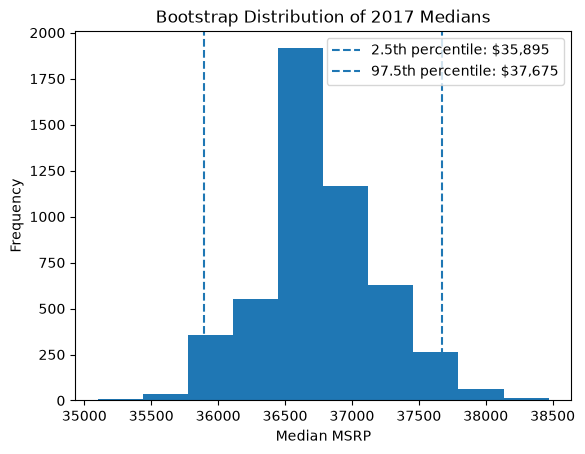

In [146]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    medians = []
    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))
    return np.array(medians)

# a, b) 2017
msrp_median = clean_2017["msrp"].median()
print(f"MSRP median for 2017: {msrp_median}")
bootstrap_medians = bootstrap_median(clean_2017["msrp"])

lower = np.percentile(bootstrap_medians, 2.5)
upper = np.percentile(bootstrap_medians, 97.5)
print(f"95% for MSRP median: [{lower}, {upper}]")


plt.hist(bootstrap_medians)
plt.axvline(lower, linestyle="--", label=f"2.5th percentile: ${lower:,.0f}")
plt.axvline(upper, linestyle="--", label=f"97.5th percentile: ${upper:,.0f}")
plt.xlabel("Median MSRP")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of 2017 Medians")
plt.legend()
plt.show()


In [147]:
clean_2017['make'].value_counts()

make
Toyota           163
Chevrolet        157
Ford             156
Nissan           117
Honda             95
BMW               79
Audi              69
Cadillac          67
GMC               64
Mercedes-Benz     61
Volkswagen        61
Dodge             51
Subaru            46
Lincoln           46
Kia               43
Hyundai           42
Buick             39
Acura             36
Lexus             34
Mitsubishi        29
Infiniti          28
Porsche           25
Chrysler          24
Mazda             24
Volvo             23
FIAT              19
Land Rover        11
Maserati          10
Genesis            3
Lotus              1
Name: count, dtype: int64

95% confidence interval for Kia MSRP: [25400.0, 31500.0]


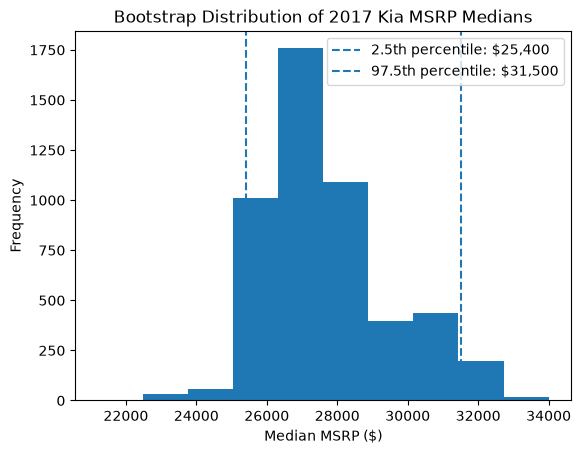

In [148]:
Kia_2017 = clean_2017[clean_2017["make"] == "Kia"]
bootstrap_medians = bootstrap_median(Kia_2017["msrp"], n_boot=5000)

lower = np.percentile(bootstrap_medians, 2.5)
upper = np.percentile(bootstrap_medians, 97.5)
print(f"95% confidence interval for Kia MSRP: [{lower}, {upper}]")

plt.hist(bootstrap_medians)
plt.axvline(lower, linestyle="--", label=f"2.5th percentile: ${lower:,.0f}")
plt.axvline(upper, linestyle="--", label=f"97.5th percentile: ${upper:,.0f}")

plt.xlabel("Median MSRP ($)")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of 2017 Kia MSRP Medians")
plt.legend()
plt.show()


**Answer:**
The Kia median MSRP interval is wider. The median is less precise since the cars for Kia is less.

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

Sample size: 505
Mean MPG: 30.895049504950496


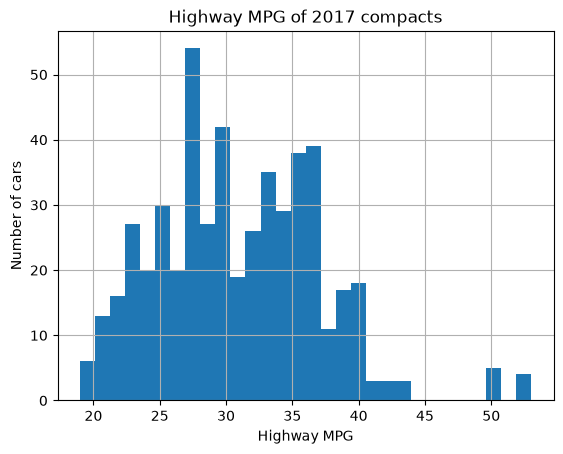

t = 3.32, p = 0.0005
make        model          
Acura       ILX                 6
            NSX                 1
Audi        A3                 12
            Q3                  6
            R8                  2
                               ..
Volkswagen  Golf Alltrack       5
            Golf GTI           10
            Golf R              4
            Golf SportWagen     4
            Tiguan              8
Length: 85, dtype: int64
mean = 31.69, t = 2.58, p = 0.0059


In [149]:
compact_2017 = clean_2017[clean_2017["vehicle_size"] == "Compact"].dropna()

print("Sample size:", compact_2017.shape[0])
print("Mean MPG:", compact_2017["highway_mpg"].mean())

compact_2017["highway_mpg"].hist(bins=30)
plt.xlabel("Highway MPG")
plt.ylabel("Number of cars")
plt.title("Highway MPG of 2017 compacts")
plt.show()

result = stats.ttest_1samp(compact_2017["highway_mpg"], 30, alternative="greater")
print(f"t = {result.statistic:.2f}, p = {result.pvalue:.4f}")

per_model = compact_2017.groupby(["make", "model"]).size()
print(per_model)

model_mpg = compact_2017.groupby(["make", "model"])["highway_mpg"].mean()
t2, p2 = stats.ttest_1samp(model_mpg, 30, alternative="greater")
print(f"mean = {model_mpg.mean():.2f}, t = {t2:.2f}, p = {p2:.4f}")

**Answer:**
The null Hypothesis is that the 2017 compacts is 30MPG 
the alternative is that 2017 compacts average over 30 MGP

There are 505 compact rows and it is well-distributed. The sample is large enough for a t-test. 
the p value is bigger for the second test. It is trusted more since there is independent observation

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [150]:
# a) compare median MSRP by transmission type
print(clean.groupby("transmission_type")["msrp"].median().round(2))
print(clean.groupby("transmission_type")["year"].median())

# b, c) Restrict to 2015–2017, overall and within each vehicle size.
clean_two_years = clean[clean["year"].between(2015, 2017)]
print("Overall median MSRP: ", clean_two_years["msrp"].median().round(2))
print("Median MSRP by vehicle size:")
print(clean_two_years.groupby("vehicle_size")["msrp"].median().round(2))

# Mann–Whitney U test for 2015–2017 compact MSRP.
automatic = clean_two_years[(clean_two_years["transmission_type"] == "AUTOMATIC") & (clean_two_years["vehicle_size"] == "Compact")]["msrp"]
manual = clean_two_years[(clean_two_years["transmission_type"] == "MANUAL") & (clean_two_years["vehicle_size"] == "Compact")]["msrp"]

print("Auto Compact Median MSRP: ", automatic.median().round(2))
print("Manual Compact Median MSRP: ", manual.median().round(2))

result = stats.mannwhitneyu(automatic, manual)
print("Mann-Whitney U test result:", result.statistic, "P-value:", result.pvalue)

transmission_type
AUTOMATED_MANUAL    43525.0
AUTOMATIC           33620.0
DIRECT_DRIVE        35825.0
MANUAL              21875.0
Name: msrp, dtype: float64
transmission_type
AUTOMATED_MANUAL    2015.0
AUTOMATIC           2015.0
DIRECT_DRIVE        2015.5
MANUAL              2008.0
Name: year, dtype: float64
Overall median MSRP:  36100.0
Median MSRP by vehicle size:
vehicle_size
Compact    27230.0
Large      44875.0
Midsize    37455.0
Name: msrp, dtype: float64
Auto Compact Median MSRP:  25995.0
Manual Compact Median MSRP:  25860.0
Mann-Whitney U test result: 317261.0 P-value: 0.20483161191397048


**Answer:**
Manual cars are not much cheaper than the auto vehnicles

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [151]:
four_door = clean[clean["number_of_doors"] == 4]["msrp"].dropna()
two_door = clean[clean["number_of_doors"] == 2]["msrp"].dropna()

print("4-door Median MSRP: ", four_door.median().round(2))
print("2-door Median MSRP: ", two_door.median().round(2))

result = stats.ttest_ind(four_door, two_door, equal_var=False)
print("Welch t-test result:", result.statistic.round(2), "P-value:", result.pvalue)


# yearly gas cost = miles * price_per_gallon / mpg
# If 12,000 miles/year and $3.50/gallon. How much does the average 4-door driver save per year?
four_door_mpg = clean[clean["number_of_doors"] == 4]["highway_mpg"]
two_door_mpg = clean[clean["number_of_doors"] == 2]["highway_mpg"]

yearly_gas_cost_four_door = 12000 * 3.5 / four_door_mpg.mean()
yearly_gas_cost_two_door = 12000 * 3.5 / two_door_mpg.mean()
print("Average yearly gas cost for 4-door driver: ", yearly_gas_cost_four_door.round(2))
print("Average yearly gas cost for 2-door driver: ", yearly_gas_cost_two_door.round(2))


print("Average yearly savings for 4-door driver: ", (yearly_gas_cost_two_door - yearly_gas_cost_four_door).round(2))


4-door Median MSRP:  31907.5
2-door Median MSRP:  32475.0
Welch t-test result: -12.81 P-value: 1.4239905621650904e-36
Average yearly gas cost for 4-door driver:  1566.89
Average yearly gas cost for 2-door driver:  1662.94
Average yearly savings for 4-door driver:  96.05


In [152]:
h_null=0
for _ in range(1000):
    four_door_sample = rng.choice(four_door_mpg, 30, replace=False)
    two_door_sample = rng.choice(two_door_mpg, 30, replace=False)
    result = stats.ttest_ind(four_door_sample, two_door_sample)
    if result.pvalue < 0.05:
        h_null += 1
print("results: ", h_null / 1000)

results:  0.126


**Answer:**
The statement would be true if looking at the p-value and gas cost.

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**



---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [153]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [154]:
# S2